# CLIP dual encoder

Aula 4 - Vision-Language Models.

1. Carregar o CLIP (ViT-B/32)
2. Olhar a arquitetura dual encoder
3. Inferência zero-shot (imagem × textos)
4. Espaço compartilhado (cosseno + UMAP 2D)
5. Vários itens na mesma imagem (presentes × opostos)

# 0. Instalando

`transformers` traz o CLIP. `pillow` + `matplotlib` para imagem e plot.

In [91]:
# %pip install -q torch transformers pillow matplotlib requests umap-learn

## 1. Imports

In [92]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor
import umap

HERE = Path.cwd()
if HERE.name != "vlms":
    HERE = Path("exemplos-aula-04/vlms")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Pasta:", HERE)

Device: cuda
Pasta: /home/thyago/luxai/deep-learning-pratica/exemplos-aula-04/vlms


## 2. Carregar o modelo

`openai/clip-vit-base-patch32` = Vision Transformer Base, patches 32×32, dual encoder imagem + texto.

In [93]:
MODEL_ID = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(MODEL_ID)
model = model.to(device).eval()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## 3. Identidade do checkpoint

Só o essencial: id, device e dimensão do espaço compartilhado.

In [94]:
cfg = model.config

print(f"modelo:    {MODEL_ID}")
print(f"device:    {device}")
print(f"embed_dim: {cfg.projection_dim}")

modelo:    openai/clip-vit-base-patch32
device:    cuda
embed_dim: 512


## 4. Fluxo dual encoder

Dois encoders independentes; a junção é só no espaço vetorial (cosine), sem cross-attention.

In [95]:
print("imagem  →  vision_model  →  visual_projection  →  vetor")
print("texto   →  text_model    →  text_projection    →  vetor")
print("depois: similaridade de cosseno entre os vetores")

imagem  →  vision_model  →  visual_projection  →  vetor
texto   →  text_model    →  text_projection    →  vetor
depois: similaridade de cosseno entre os vetores


## 5. Encoder visual

ViT: imagem vira sequência de patches e passa por um Transformer.

In [96]:
v = cfg.vision_config

print(f"módulo: {type(model.vision_model).__name__}")
print(f"hidden: {v.hidden_size}")
print(f"layers: {v.num_hidden_layers}")
print(f"heads:  {v.num_attention_heads}")
print(f"patch:  {v.patch_size}")
print(f"image:  {v.image_size}")

módulo: CLIPVisionModel
hidden: 768
layers: 12
heads:  12
patch:  32
image:  224


## 6. Encoder de texto

Encoder Transformer sobre tokens; o embedding usado no CLIP vem do token EOS / pooled.

In [97]:
t = cfg.text_config

print(f"módulo: {type(model.text_model).__name__}")
print(f"hidden: {t.hidden_size}")
print(f"layers: {t.num_hidden_layers}")
print(f"heads:  {t.num_attention_heads}")
print(f"vocab:  {t.vocab_size}")
print(f"ctx:    {t.max_position_embeddings}")

módulo: CLIPTextModel
hidden: 512
layers: 12
heads:  8
vocab:  49408
ctx:    77


## 7. Projeções

As Linear jogam visão/texto no mesmo `embed_dim` - o espaço compartilhado onde comparamos imagem e texto.

In [98]:
print(f"visual_projection: {model.visual_projection}")
print(f"text_projection:   {model.text_projection}")

visual_projection: Linear(in_features=768, out_features=512, bias=False)
text_projection:   Linear(in_features=512, out_features=512, bias=False)


## 8. Contagem de parâmetros

Quase tudo está nos dois encoders. As projeções são pequenas - o alinhamento vive no treino contrastivo.

In [99]:
def count_params(module):
    return sum(p.numel() for p in module.parameters())

total = count_params(model)
vision = count_params(model.vision_model) + count_params(model.visual_projection)
text = count_params(model.text_model) + count_params(model.text_projection)

print(f"total:  {total / 1e6:.1f}M")
print(f"vision: {vision / 1e6:.1f}M")
print(f"text:   {text / 1e6:.1f}M")

total:  151.3M
vision: 87.8M
text:   63.4M


## 9. Imagem de exemplo

Baixamos uma foto pública só para a demo.

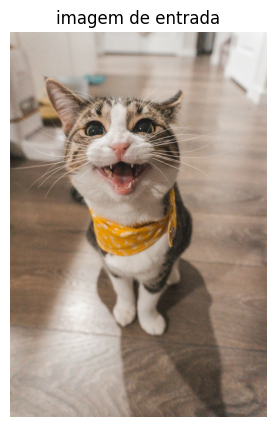

In [100]:
IMAGE_URL = "https://images.unsplash.com/photo-1543852786-1cf6624b9987?w=640"

response = requests.get(IMAGE_URL, timeout=30)
response.raise_for_status()
image = Image.open(BytesIO(response.content)).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("imagem de entrada")
plt.show()

## 10. Candidatos de texto (zero-shot)

Zero-shot = classificar **sem treinar** no seu dataset. Só descrevemos as classes em linguagem natural.

In [101]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a bus",
    "a photo of a person riding a bicycle",
    "a photo of a pizza",
    "a photo of a bird",
    "a photo of a car",
    "a photo of a tree",
]
texts

['a photo of a cat',
 'a photo of a dog',
 'a photo of a bus',
 'a photo of a person riding a bicycle',
 'a photo of a pizza',
 'a photo of a bird',
 'a photo of a car',
 'a photo of a tree']

## 11. Pré-processar

O processor cuida de resize/normalize da imagem e tokenização do texto.

In [102]:
inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True,
)
inputs = {k: v.to(device) for k, v in inputs.items()}

{k: tuple(v.shape) for k, v in inputs.items()}

{'input_ids': (8, 10),
 'attention_mask': (8, 10),
 'pixel_values': (1, 3, 224, 224)}

## 12. Inferência: embeddings alinhados

`get_image_features` / `get_text_features` passam por encoder + projeção. Normalizamos e medimos cosine similarity.

In [103]:
# transformers>=5: get_*_features devolve BaseModelOutputWithPooling;
# o embedding projetado está em .pooler_output
with torch.no_grad():
    image_out = model.get_image_features(pixel_values=inputs["pixel_values"])
    text_out = model.get_text_features(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
    )
    image_embeds = image_out.pooler_output
    text_embeds = text_out.pooler_output

image_embeds = image_embeds / image_embeds.norm(dim=-1, keepdim=True)
text_embeds = text_embeds / text_embeds.norm(dim=-1, keepdim=True)

print("image_embeds:", tuple(image_embeds.shape))
print("text_embeds:", tuple(text_embeds.shape))

image_embeds: (1, 512)
text_embeds: (8, 512)


## 13. Similaridade de cosseno

Embeddings já normalizados → produto interno = cosseno.
Quanto maior o valor, mais a imagem "combina" com aquele texto.

In [104]:
sims = (image_embeds @ text_embeds.T).squeeze()
order = sims.argsort(descending=True)

print("similaridade (cosseno):")
for i in order:
    print(f"{sims[i]:.3f}  {texts[i]}")

similaridade (cosseno):
0.286  a photo of a cat
0.242  a photo of a dog
0.223  a photo of a pizza
0.212  a photo of a bird
0.201  a photo of a bus
0.192  a photo of a car
0.179  a photo of a tree
0.169  a photo of a person riding a bicycle


## 14. Visualizar o ranking zero-shot

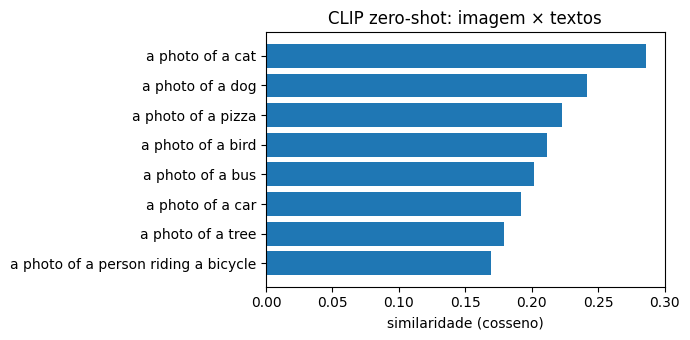

In [105]:
scores = sims.detach().cpu().numpy()
order = scores.argsort()[::-1]

plt.figure(figsize=(7, 3.5))
plt.barh([texts[i] for i in order][::-1], scores[order][::-1])
plt.xlabel("similaridade (cosseno)")
plt.title("CLIP zero-shot: imagem × textos")
plt.tight_layout()
plt.show()

## 15. Espaço compartilhado em 2D (UMAP)

Reduzimos imagem + textos com **UMAP** só para visualizar quem ficou perto de quem.
O ranking real continua sendo o cosseno em 512D.


/home/thyago/miniconda3/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


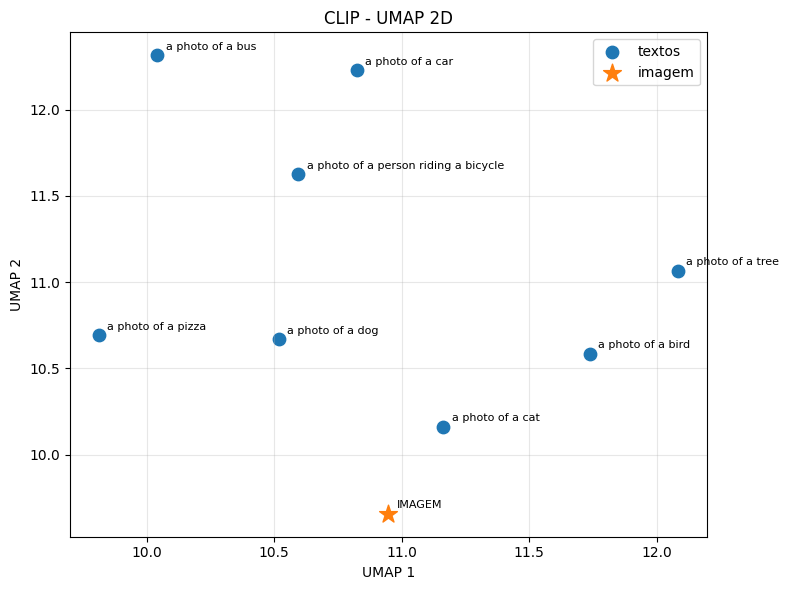

In [106]:
X = torch.cat([image_embeds, text_embeds], dim=0).detach().cpu().numpy()
labels = ["IMAGEM"] + texts

xy = umap.UMAP(
    n_components=2,
    n_neighbors=3,
    min_dist=0.1,
    metric="cosine",
    random_state=0,
).fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(xy[1:, 0], xy[1:, 1], s=80, label="textos")
ax.scatter(xy[0, 0], xy[0, 1], s=180, marker="*", label="imagem")
for (x, y), lab in zip(xy, labels):
    ax.annotate(lab, (x, y), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_title("CLIP - UMAP 2D")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Vários itens na mesma imagem

Zero-shot também funciona com **mais de um conceito** na foto.
Aqui: 3 itens que estão na imagem (`dog`, `cross`, `bible`) vs 3 opostos / ausentes (`cat`, `pizza`, `smartphone`).

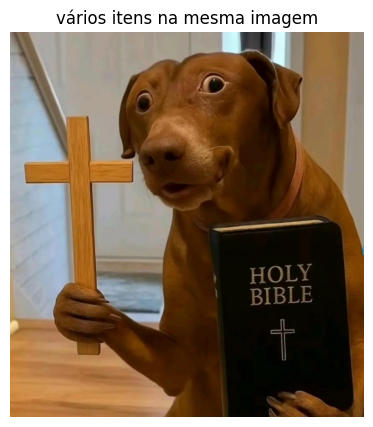

In [107]:
MULTI_URL = (
    "https://kusart.com/library/meme/scared-dog-meme/scared-dog-meme-whatis-1.jpg"
)

response = requests.get(MULTI_URL, timeout=30)
response.raise_for_status()
image_multi = Image.open(BytesIO(response.content)).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image_multi)
plt.axis("off")
plt.title("vários itens na mesma imagem")
plt.show()

presentes vs opostos (cosseno):
0.277  ✓ presente  a photo of a holy bible
0.268  ✓ presente  a photo of a dog
0.264  ✓ presente  a photo of a wooden cross
0.219  ✗ oposto  a photo of a cat
0.218  ✗ oposto  a photo of a pizza
0.214  ✗ oposto  a photo of a smartphone


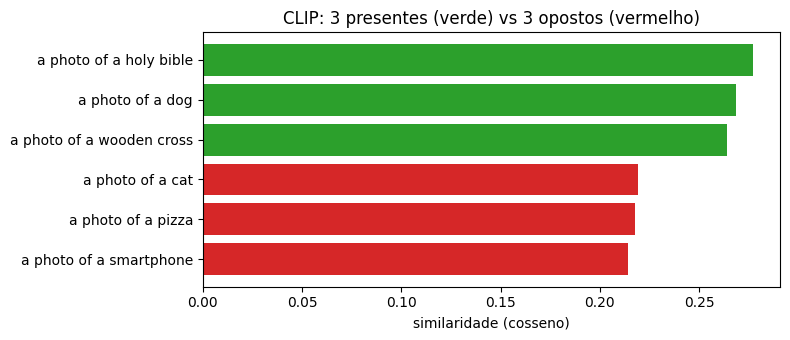

In [108]:
present = [
    "a photo of a dog",
    "a photo of a wooden cross",
    "a photo of a holy bible",
]
opposite = [
    "a photo of a cat",
    "a photo of a pizza",
    "a photo of a smartphone",
]
texts_multi = present + opposite

inputs_multi = processor(
    text=texts_multi,
    images=image_multi,
    return_tensors="pt",
    padding=True,
)
inputs_multi = {k: v.to(device) for k, v in inputs_multi.items()}

with torch.no_grad():
    image_out = model.get_image_features(pixel_values=inputs_multi["pixel_values"])
    text_out = model.get_text_features(
        input_ids=inputs_multi["input_ids"],
        attention_mask=inputs_multi["attention_mask"],
    )
    img_e = image_out.pooler_output
    txt_e = text_out.pooler_output

img_e = img_e / img_e.norm(dim=-1, keepdim=True)
txt_e = txt_e / txt_e.norm(dim=-1, keepdim=True)

sims_multi = (img_e @ txt_e.T).squeeze()
order = sims_multi.argsort(descending=True)

print("presentes vs opostos (cosseno):")
for i in order:
    tag = "✓ presente" if texts_multi[i] in present else "✗ oposto"
    print(f"{sims_multi[i]:.3f}  {tag}  {texts_multi[i]}")

scores = sims_multi.detach().cpu().numpy()
colors = ["#2ca02c" if t in present else "#d62728" for t in texts_multi]
order_np = scores.argsort()[::-1]

plt.figure(figsize=(8, 3.5))
plt.barh(
    [texts_multi[i] for i in order_np][::-1],
    scores[order_np][::-1],
    color=[colors[i] for i in order_np][::-1],
)
plt.xlabel("similaridade (cosseno)")
plt.title("CLIP: 3 presentes (verde) vs 3 opostos (vermelho)")
plt.tight_layout()
plt.show()

## 17. Ponto interessante: por que dual encoder escala?

Na inferência, imagem e texto são encodeados **separadamente**. Dá para pré-computar embeddings de um catálogo enorme de textos (ou imagens) e só comparar com cosine - retrieval barato. Cross-attention multimodal (tipo VLMs generativos) é mais expressivo, mas bem mais caro em escala.

## 18. Liberar VRAM

Apaga o modelo da memória e chama `empty_cache` - útil antes de rodar outro notebook na mesma GPU.

In [109]:
import gc

for name in [
    "model",
    "processor",
    "inputs",
    "image_embeds",
    "text_embeds",
    "out",
    "inputs_multi",
    "image_multi",
    "img_e",
    "txt_e",
]:
    globals().pop(name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free, total = torch.cuda.mem_get_info()
    print(f"VRAM livre: {free / 1e9:.2f} / {total / 1e9:.2f} GB")
else:
    print("CPU only")

VRAM livre: 1.69 / 6.05 GB
